# Control charts for failure-linked sensors

Individuals and Moving Range (I-MR) charts for the four sensors most associated with failures (sensor_59, sensor_103, sensor_510, sensor_28), with Western Electric rules 1 (point beyond 3σ) and 2 (8 points in a row on one side of the centre line). Limits are set from a baseline period and then used to monitor later runs.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

os.makedirs("../results", exist_ok=True)

In [2]:
df = pd.read_csv("../data/secom_clean.csv", parse_dates=["timestamp"])
chosen = ["sensor_59", "sensor_103", "sensor_510", "sensor_28"]

In [3]:
def imr_chart(df, sensor, n_baseline=500, tag=""):
    """Individuals & Moving Range (I-MR) chart with Western Electric rules 1 and 2."""
    d = df[["timestamp", "fail", sensor]].dropna().reset_index(drop=True)
    x = d[sensor].values

    #Control limits from a baseline period (first ~month of production)
    base = x[:n_baseline]
    centre = base.mean()
    mr_bar = np.abs(np.diff(base)).mean()
    sigma = mr_bar / 1.128            #standard SPC estimate of short-term variation
    ucl, lcl = centre + 3 * sigma, centre - 3 * sigma

    #Rule 1: any point beyond 3 sigma
    rule1 = (x > ucl) | (x < lcl)

    #Rule 2: 8 or more points in a row on the same side of the centre line
    side = np.sign(x - centre)
    rule2 = np.zeros(len(x), dtype=bool)
    run, prev = 0, 0
    for i, s in enumerate(side):
        run = run + 1 if (s == prev and s != 0) else 1
        prev = s
        if run >= 8:
            rule2[i] = True

    d["rule1"], d["rule2"] = rule1, rule2
    d["out_of_control"] = rule1 | rule2

    # --- Plot ---
    fail = d["fail"].values
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 6), sharex=True,
                                   gridspec_kw={"height_ratios": [2, 1]})
    ax1.plot(d.index, x, color="grey", lw=0.6, marker=".", ms=2)
    ax1.axhline(centre, color="green", label="Centre line")
    ax1.axhline(ucl, color="red", ls="--", label="±3σ limits")
    ax1.axhline(lcl, color="red", ls="--")
    ax1.axvline(n_baseline, color="black", ls=":", label="End of baseline")
    ax1.scatter(d.index[rule1], x[rule1], color="orange", s=20, zorder=3, label="Beyond 3σ")
    ax1.scatter(d.index[fail], x[fail], color="red", marker="x", s=25, zorder=4, label="Failed run")
    ax1.set_title(f"I-MR chart: {sensor}")
    ax1.set_ylabel("Value")
    ax1.legend(loc="upper left", fontsize=8)

    mr = np.abs(np.diff(x))
    ax2.plot(d.index[1:], mr, color="grey", lw=0.6)
    ax2.axhline(mr_bar, color="green")
    ax2.axhline(3.267 * mr_bar, color="red", ls="--")
    ax2.set_ylabel("Moving range")
    ax2.set_xlabel("Run (in time order)")

    plt.tight_layout()
    plt.savefig(f"../results/imr_{sensor}{tag}.png", dpi=150)
    plt.show()
    return d

## Initial control charts (baseline: first 500 runs)

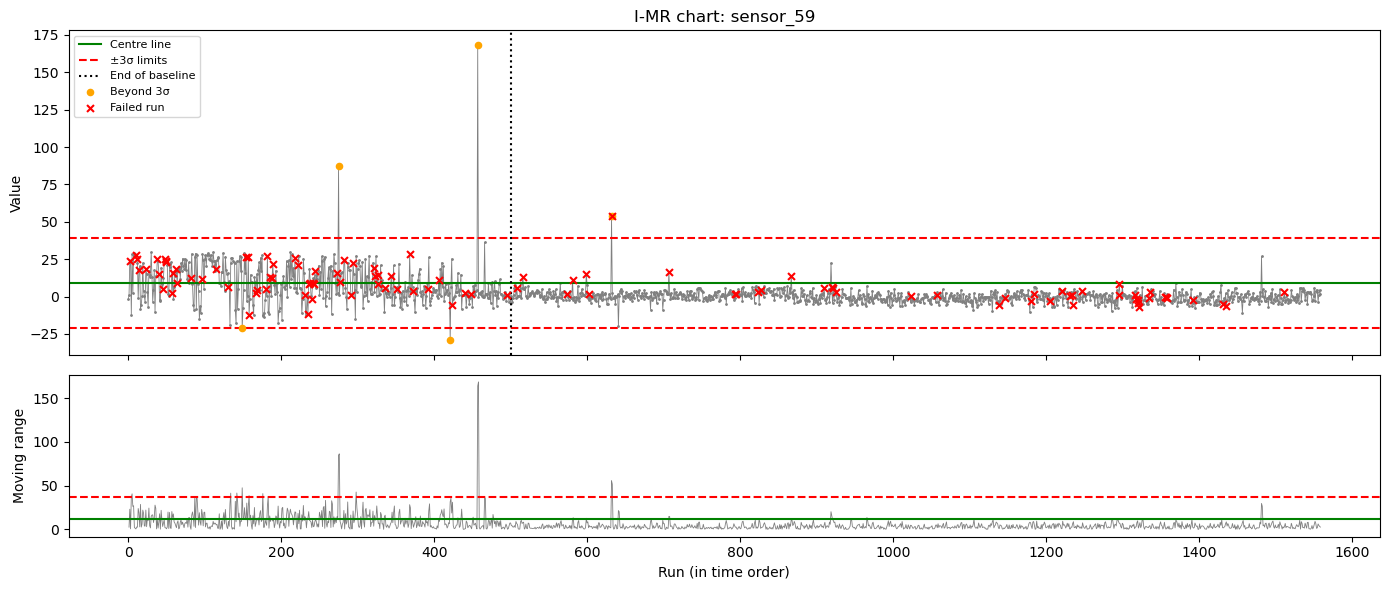

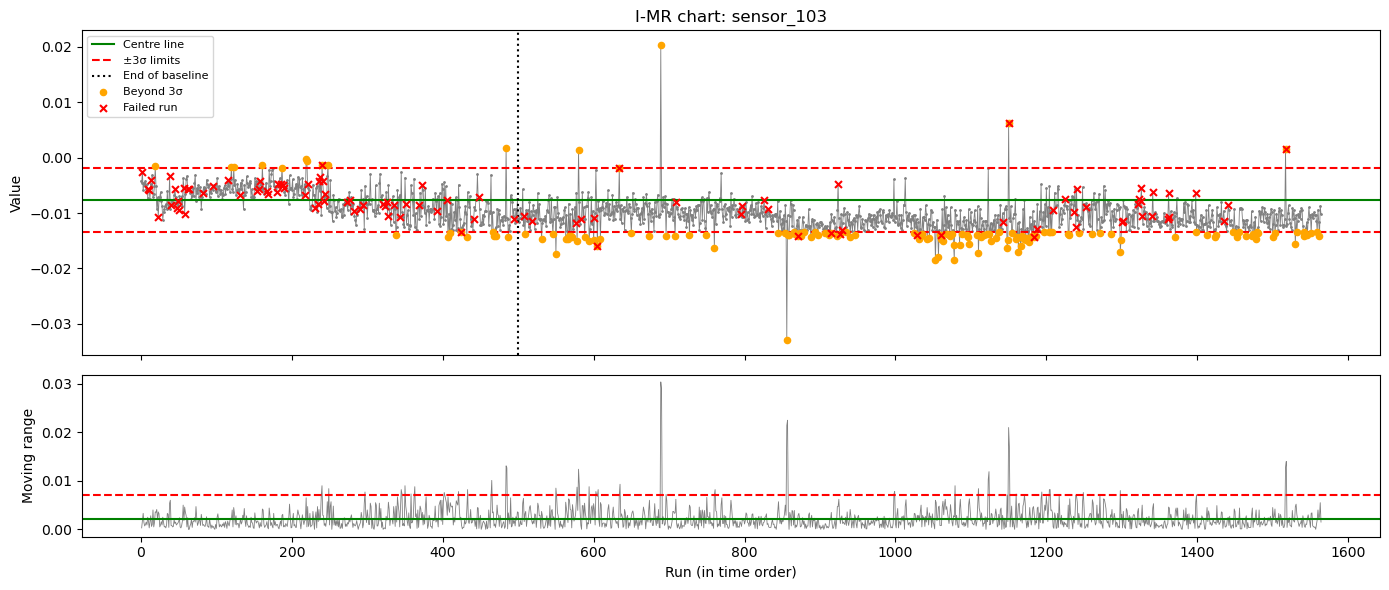

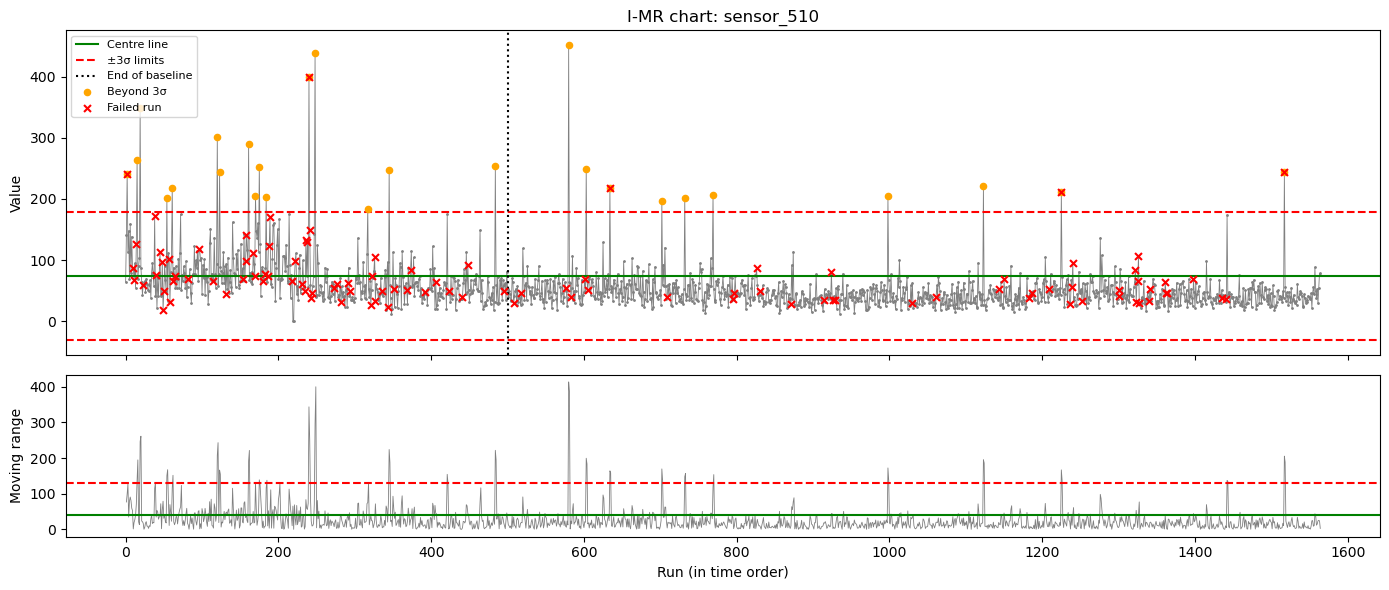

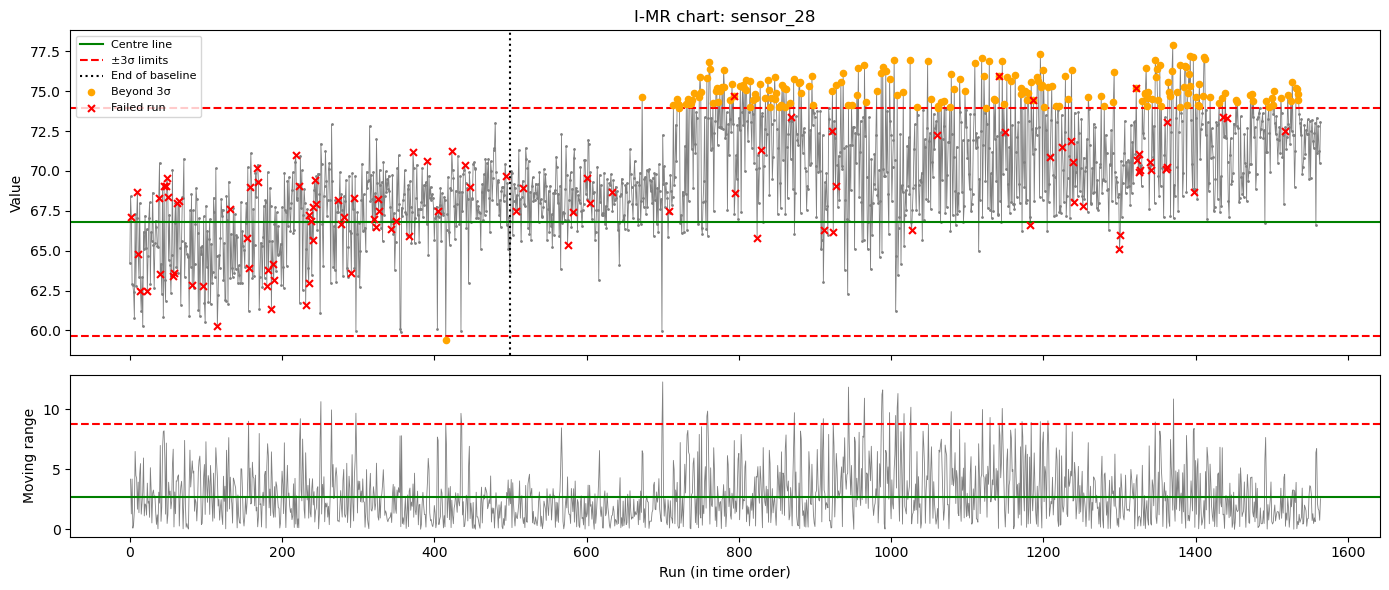

In [4]:
charts = {s: imr_chart(df, s) for s in chosen}

In [5]:
rows = []
for s, d in charts.items():
    ooc = d["out_of_control"]
    rows.append({
        "sensor": s,
        "% beyond 3σ": round(d["rule1"].mean() * 100, 1),
        "% in 8-point runs": round(d["rule2"].mean() * 100, 1),
        "fail rate when out of control (%)": round(d.loc[ooc, "fail"].mean() * 100, 1),
        "fail rate when in control (%)": round(d.loc[~ooc, "fail"].mean() * 100, 1),
    })
summary = pd.DataFrame(rows)
summary

,sensor,% beyond 3σ,% in 8-point runs,fail rate when out of control (%),fail rate when in control (%)
0,sensor_59,0.3,67.7,3.9,12.6
1,sensor_103,9.8,53.2,5.0,8.8
2,sensor_510,1.7,45.6,4.6,8.5
3,sensor_28,12.5,41.4,3.7,9.0


The initial charts flag 41–68% of runs as out of control, and out-of-control runs fail *less* often than in-control runs, which is the opposite of what would be expected. The cells below investigate why.

In [6]:
# 1. Did the failure rate change after the baseline period?
print(f"Fail rate in first 500 runs: {df['fail'].iloc[:500].mean()*100:.1f}%")
print(f"Fail rate after:             {df['fail'].iloc[500:].mean()*100:.1f}%\n")

# 2. Did each sensor's average shift after the baseline?
for s, d in charts.items():
    base_mean = d[s].iloc[:500].mean()
    later_mean = d[s].iloc[500:].mean()
    sd = d[s].iloc[:500].std()
    print(f"{s}: baseline mean {base_mean:.4g}, later mean {later_mean:.4g}, "
          f"shift = {(later_mean - base_mean)/sd:+.2f} baseline SDs")

# 3. Fair comparison: only look at runs AFTER the baseline
print()
for s, d in charts.items():
    post = d.iloc[500:]
    rates = post.groupby("out_of_control")["fail"].mean() * 100
    print(f"{s}: after baseline, fail rate in control {rates.get(False, float('nan')):.1f}% "
          f"vs out of control {rates.get(True, float('nan')):.1f}%")

Fail rate in first 500 runs: 11.8%
Fail rate after:             4.2%

sensor_59: baseline mean 9.122, later mean 0.05368, shift = -0.65 baseline SDs
sensor_103: baseline mean -0.007604, later mean -0.01081, shift = -1.12 baseline SDs
sensor_510: baseline mean 74.35, later mean 47.04, shift = -0.56 baseline SDs
sensor_28: baseline mean 66.8, later mean 70.77, shift = +1.47 baseline SDs

sensor_59: after baseline, fail rate in control 13.6% vs out of control 3.6%
sensor_103: after baseline, fail rate in control 6.0% vs out of control 3.3%
sensor_510: after baseline, fail rate in control 4.7% vs out of control 3.9%
sensor_28: after baseline, fail rate in control 4.9% vs out of control 3.8%


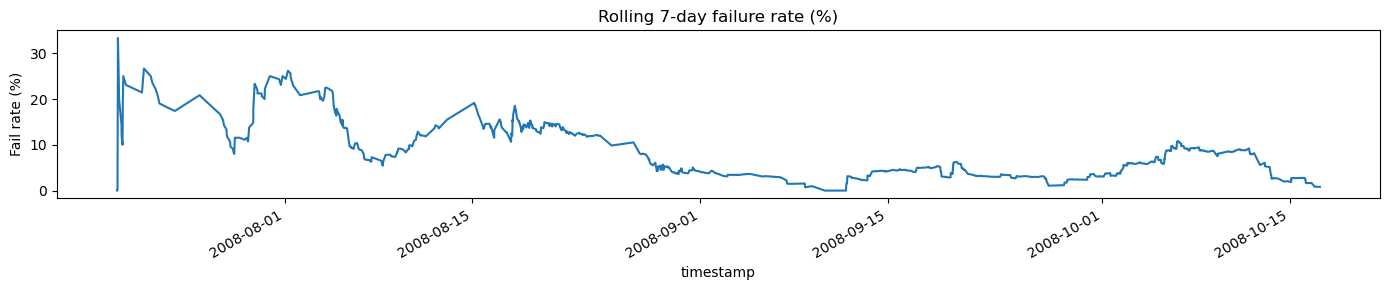

In [7]:
weekly = df.set_index("timestamp")["fail"].rolling("7D").mean() * 100
weekly.plot(figsize=(14, 3), title="Rolling 7-day failure rate (%)")
plt.ylabel("Fail rate (%)")
plt.tight_layout()
plt.savefig("../results/rolling_fail_rate.png", dpi=150)
plt.show()

In [8]:
from scipy import stats

fails = df["fail"].values
best_p, best_i = 1, None
for i in range(200, len(df) - 200):          # keep at least 200 runs on each side
    before, after = fails[:i], fails[i:]
    table = [[before.sum(), len(before) - before.sum()],
             [after.sum(),  len(after)  - after.sum()]]
    p = stats.fisher_exact(table)[1]
    if p < best_p:
        best_p, best_i = p, i

shift_date = df["timestamp"].iloc[best_i]
print(f"Most likely change point: run {best_i}, {shift_date}")
print(f"Fail rate before: {fails[:best_i].mean()*100:.1f}%, after: {fails[best_i:].mean()*100:.1f}%")

Most likely change point: run 374, 2008-08-21 18:39:00
Fail rate before: 14.2%, after: 4.3%


## Finding: a process change on 21 August 2008

- Using the first 500 runs as the control-chart baseline flagged 41-68% of later runs as out of control, and, unexpectedly, out-of-control runs failed less often.
- A change-point search on the pass/fail sequence located a shift at run 374 (21 August 2008): the failure rate fell from 14.2% before to 4.3% after, a reduction of about 70%. The rolling 7-day failure rate confirms the drop visually.
- All four selected sensors shifted around this time (by 0.6-1.5 baseline standard deviations), each away from the levels associated with failure.
- This indicates a process change (e.g. an adjustment or fix) that substantially improved yield. The original baseline represented the poorer, pre-change process, so it was not a valid reference for control limits.
- The control charts were therefore re-baselined on the post change period.

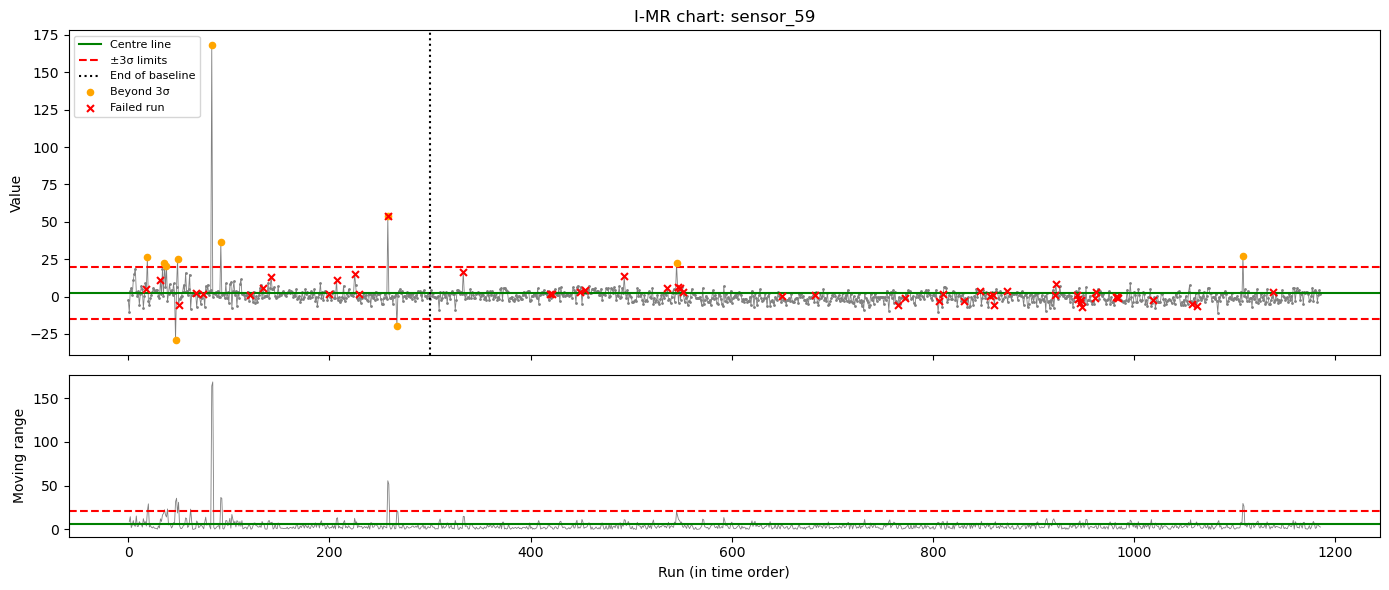

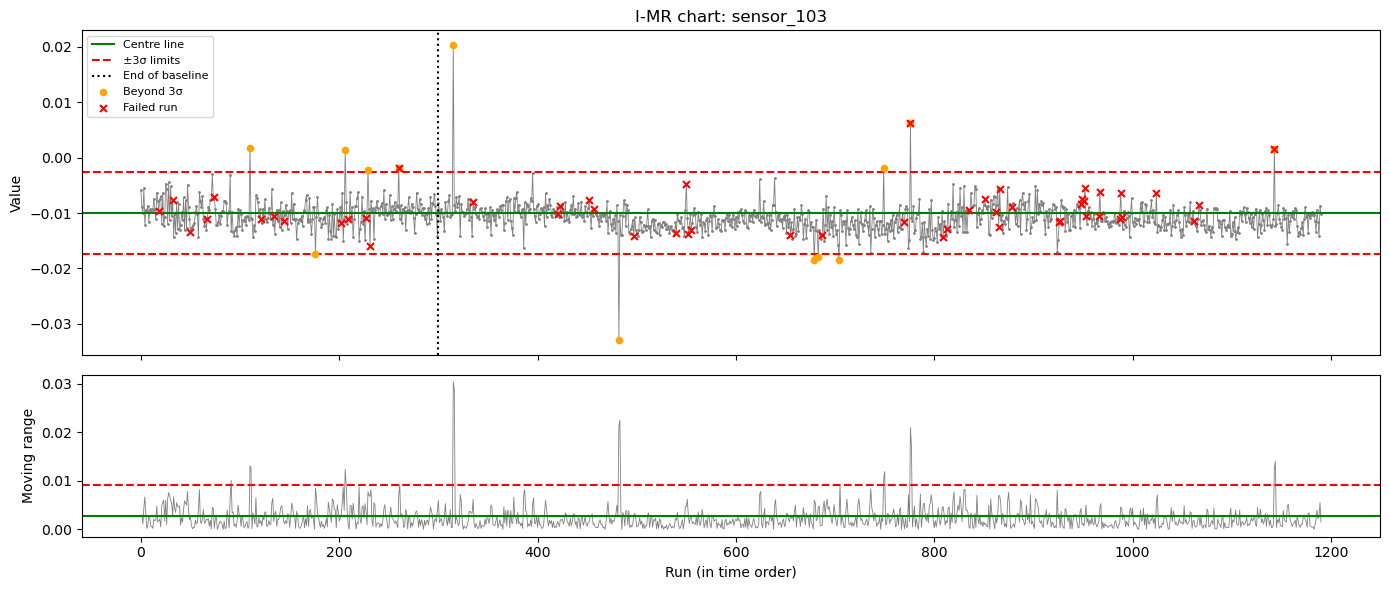

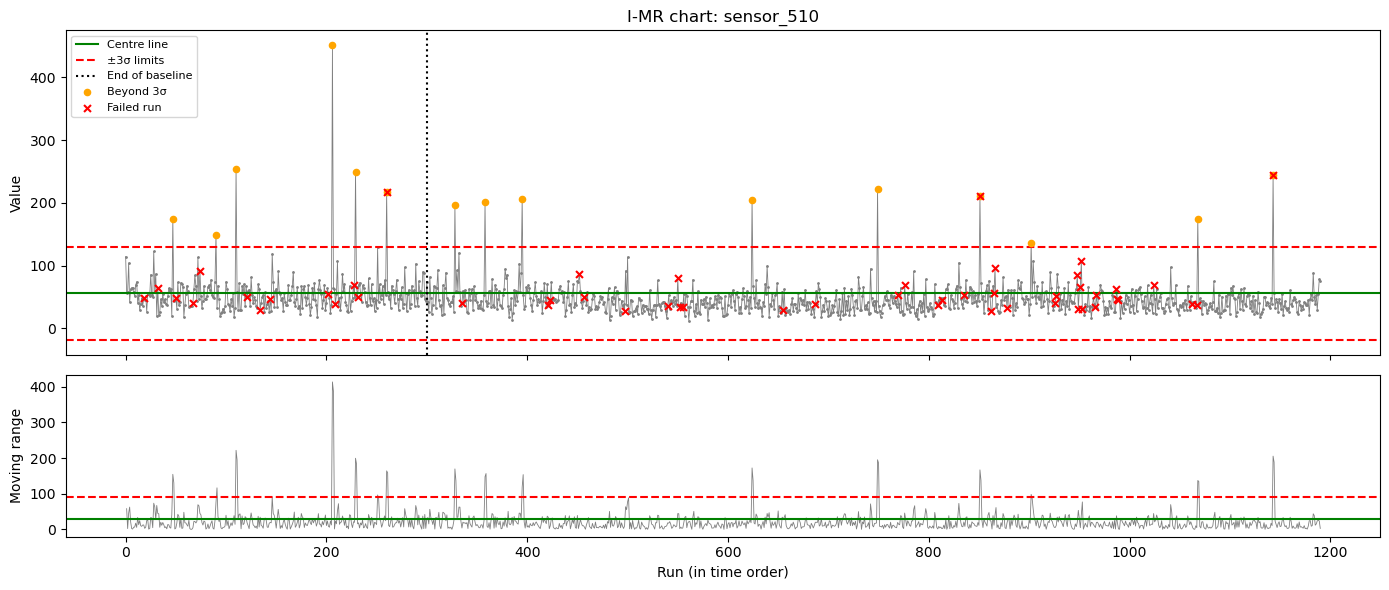

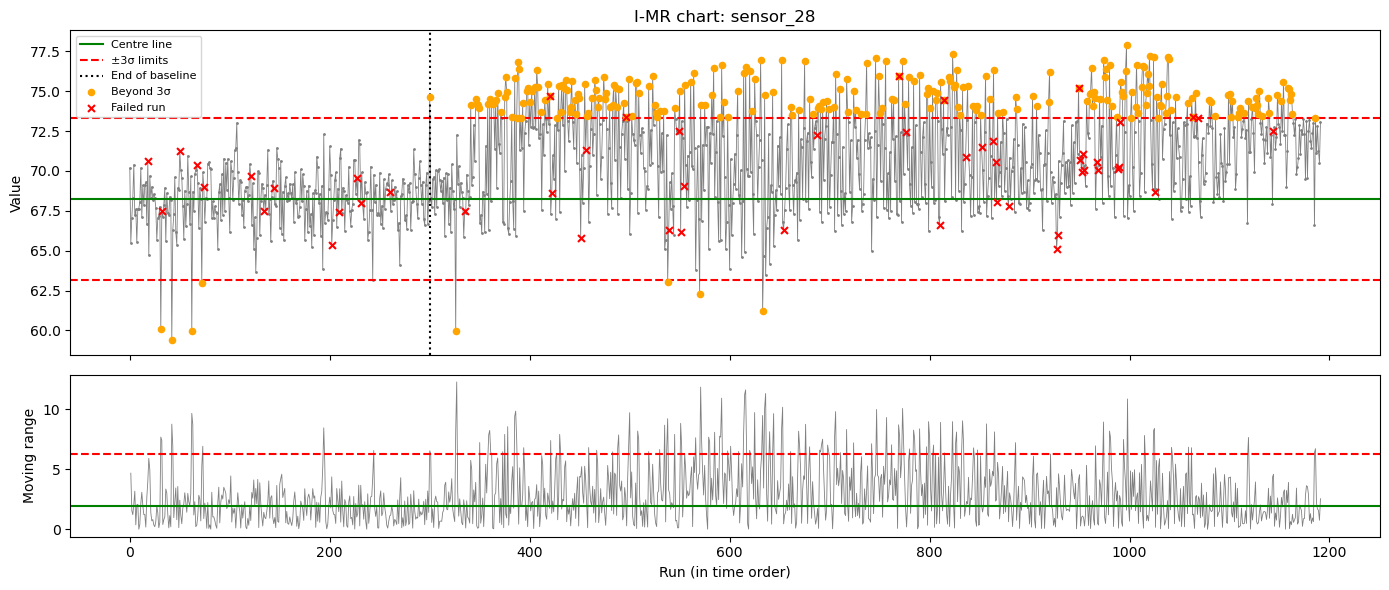

,sensor,% beyond 3σ,% in 8-point runs,fail rate out of control (%),fail rate in control (%)
0,sensor_59,0.2,21.1,3.2,4.6
1,sensor_103,0.9,14.1,4.5,4.2
2,sensor_510,1.0,21.2,4.0,4.3
3,sensor_28,28.6,22.6,3.2,5.0


In [9]:
df_post = df[df["timestamp"] >= shift_date].reset_index(drop=True)

charts_post = {s: imr_chart(df_post, s, n_baseline=300, tag="_post_change") for s in chosen}

rows = []
for s, d in charts_post.items():
    monitor = d.iloc[300:]            #judge only the runs after the new baseline
    ooc = monitor["out_of_control"]
    rows.append({
        "sensor": s,
        "% beyond 3σ": round(monitor["rule1"].mean() * 100, 1),
        "% in 8-point runs": round(monitor["rule2"].mean() * 100, 1),
        "fail rate out of control (%)": round(monitor.loc[ooc, "fail"].mean() * 100, 1),
        "fail rate in control (%)": round(monitor.loc[~ooc, "fail"].mean() * 100, 1),
    })
pd.DataFrame(rows)

## Re-baselined control charts (post-change period)

- Control limits recalculated from the first 300 runs after the process change, then used to monitor subsequent runs.
- Rule 2 flags fell substantially (e.g. sensor_103: 53% to 14%), and beyond-3σ rates for sensor_59, sensor_103 and sensor_510 are now close to the ~0.3% expected for a stable process.
- sensor_28
-  still shows 28.6% of points beyond 3σ, indicating slow drift or level changes that the moving-range estimate of variation does not capture.
- After the process change, fail rates are similar for in-control and out-of-control runs (3 to 6%), with only ~40 failures in this period. The selected sensors explain the earlier yield improvement, but do not individually predict the remaining failures, which likely depend on other or combined variables.